In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("data/raw/ not found above " + str(start))

RAW_DIR = find_project_root() / "data" / "raw"

index_names = ["unit", "cycle"]
setting_names = [f"setting_{i}" for i in range(1, 4)]
sensor_names = [f"sensor_{i}" for i in range(1, 22)]
col_names = index_names + setting_names + sensor_names

train = pd.read_csv(RAW_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=col_names)
print(train.shape)

(20631, 26)


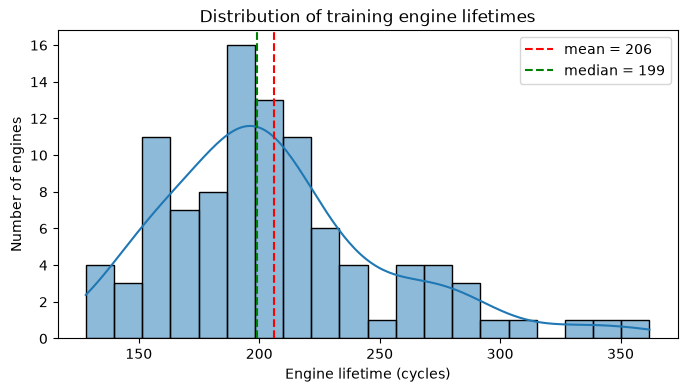

In [2]:
life = train.groupby("unit")["cycle"].max()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(life, bins=20, kde=True, ax=ax)
ax.axvline(life.mean(), color="red", linestyle="--", label=f"mean = {life.mean():.0f}")
ax.axvline(life.median(), color="green", linestyle="--", label=f"median = {life.median():.0f}")
ax.set_xlabel("Engine lifetime (cycles)")
ax.set_ylabel("Number of engines")
ax.set_title("Distribution of training engine lifetimes")
ax.legend()
plt.show()

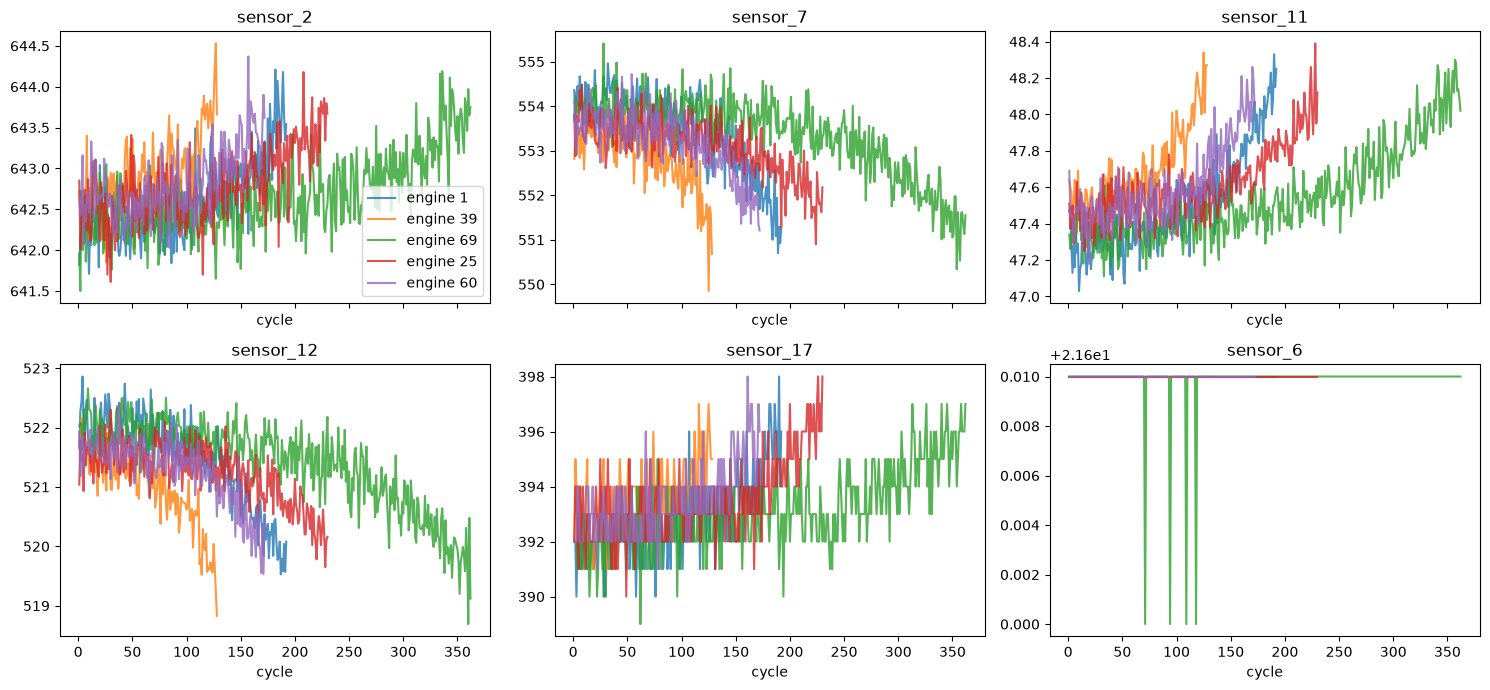

In [3]:
sensors_to_plot = ["sensor_2", "sensor_7", "sensor_11", "sensor_12", "sensor_17", "sensor_6"]
engines_to_plot = [1, 39, 69, 25, 60]   # includes the shortest (39) and longest (69) lived

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, sensor in zip(axes.ravel(), sensors_to_plot):
    for u in engines_to_plot:
        d = train[train["unit"] == u]
        ax.plot(d["cycle"], d[sensor], label=f"engine {u}", alpha=0.8)
    ax.set_title(sensor)
    ax.set_xlabel("cycle")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [4]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
setting_1   -0.003198
setting_2   -0.001948
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
Name: RUL, dtype: float64


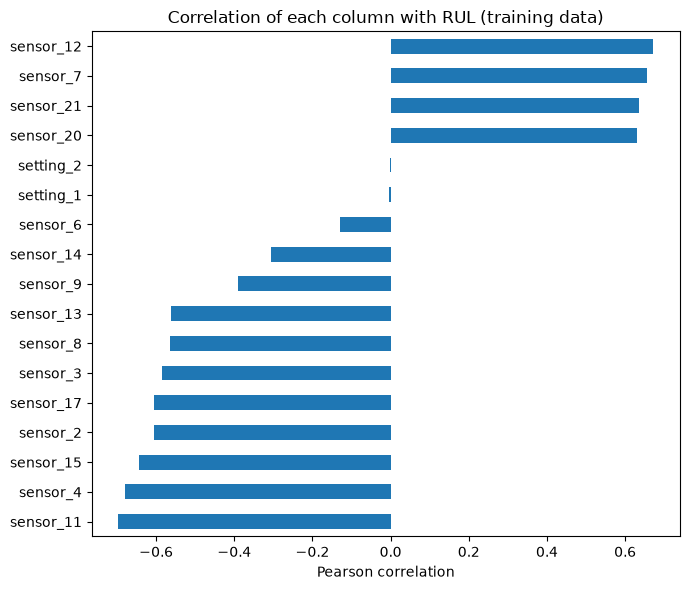

In [5]:
varying = [c for c in setting_names + sensor_names if train[c].nunique() > 1]
corr = train[varying + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
print(corr)

fig, ax = plt.subplots(figsize=(7, 6))
corr.plot(kind="barh", ax=ax)
ax.set_title("Correlation of each column with RUL (training data)")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

In [6]:
# For each sensor, compare mean of first 20% vs last 20% of each engine's life
def drift(sensor):
    out = []
    for u, d in train.groupby("unit"):
        n = len(d)
        k = max(1, int(0.2 * n))
        out.append(d[sensor].iloc[-k:].mean() - d[sensor].iloc[:k].mean())
    return np.array(out)

summary = pd.DataFrame({
    s: {"mean_drift": drift(s).mean(), "pct_engines_up": (drift(s) > 0).mean() * 100}
    for s in varying if s.startswith("sensor")
}).T
summary.sort_values("pct_engines_up")

,mean_drift,pct_engines_up
sensor_7,-1.745689,0.0
sensor_21,-0.208198,0.0
sensor_20,-0.345573,0.0
sensor_12,-1.489817,0.0
sensor_6,0.000427,51.0
sensor_14,19.437290,58.0
sensor_9,27.943744,71.0
sensor_2,0.908335,100.0
sensor_11,0.559618,100.0
sensor_8,0.118961,100.0


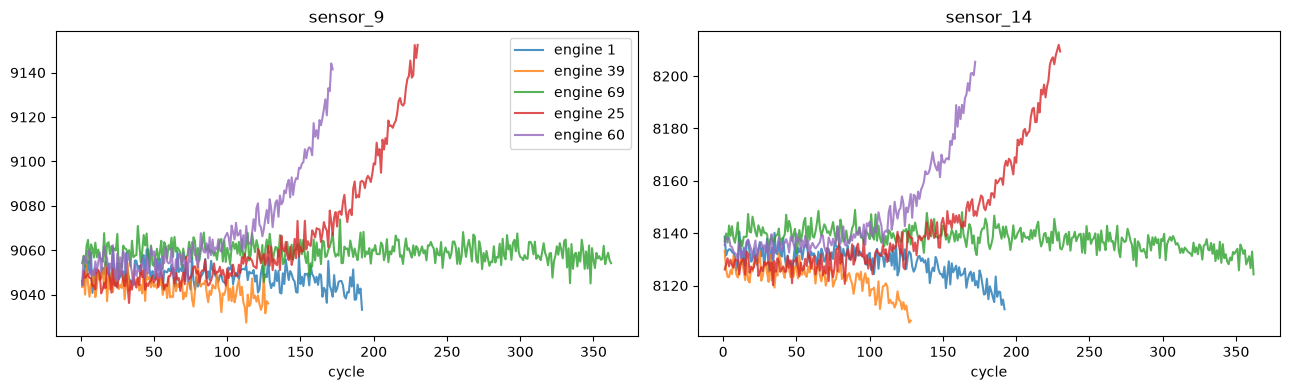

In [7]:
uncertain = ["sensor_9", "sensor_14"]
engines_to_plot = [1, 39, 69, 25, 60]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, sensor in zip(axes, uncertain):
    for u in engines_to_plot:
        d = train[train["unit"] == u]
        ax.plot(d["cycle"], d[sensor], label=f"engine {u}", alpha=0.8)
    ax.set_title(sensor)
    ax.set_xlabel("cycle")
axes[0].legend()
plt.tight_layout()
plt.show()

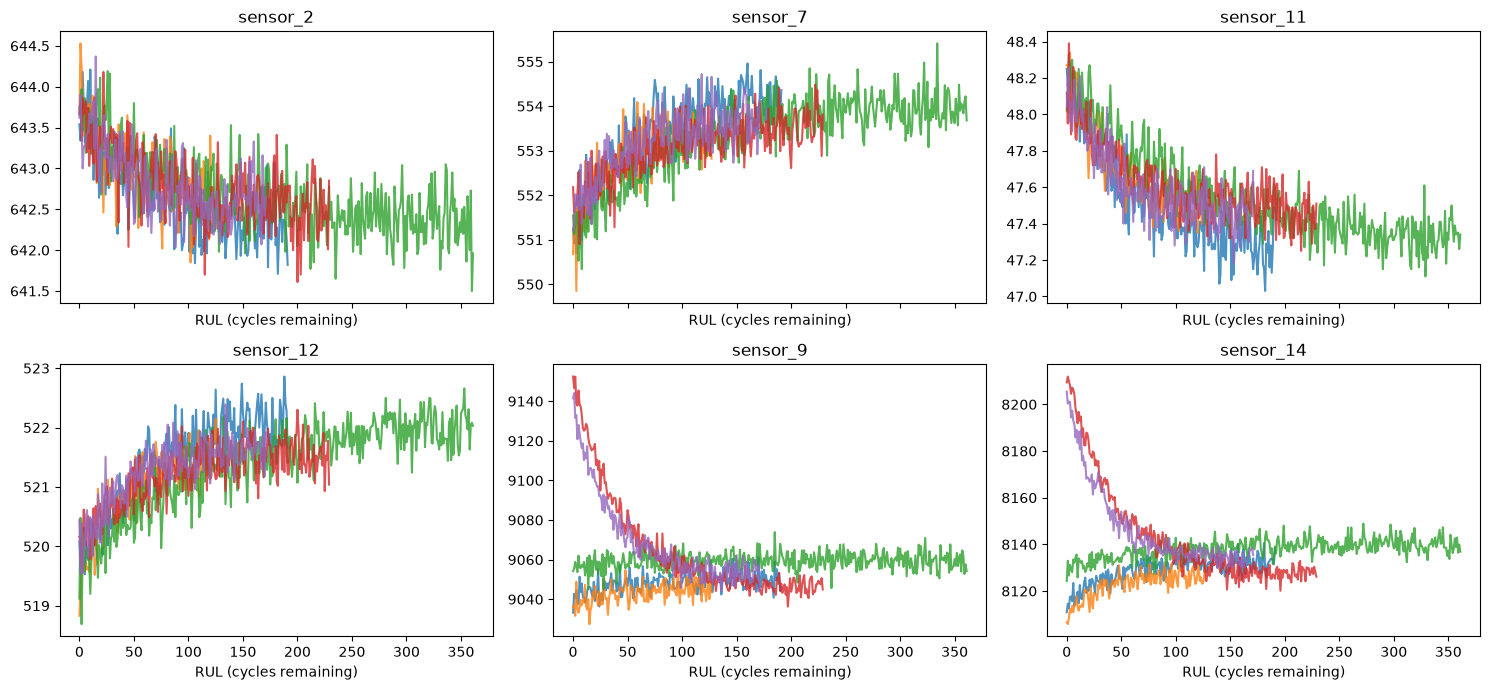

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, sensor in zip(axes.ravel(), ["sensor_2", "sensor_7", "sensor_11", "sensor_12", "sensor_9", "sensor_14"]):
    for u in engines_to_plot:
        d = train[train["unit"] == u]
        ax.plot(d["RUL"], d[sensor], alpha=0.8)
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles remaining)")
    axes[0, 0].invert_xaxis()   # shared axis, so one call flips all six panels
plt.tight_layout()
plt.show()

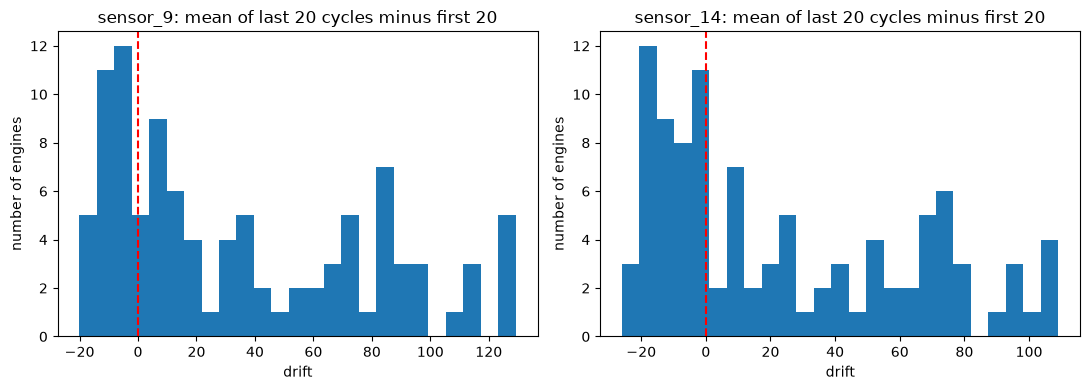

In [10]:
def end_minus_start(sensor, k=20):
    vals = []
    for u, d in train.groupby("unit"):
        vals.append(d[sensor].iloc[-k:].mean() - d[sensor].iloc[:k].mean())
    return np.array(vals)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, ["sensor_9", "sensor_14"]):
    v = end_minus_start(s)
    ax.hist(v, bins=25)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{s}: mean of last 20 cycles minus first 20")
    ax.set_xlabel("drift")
    ax.set_ylabel("number of engines")
plt.tight_layout()
plt.show()

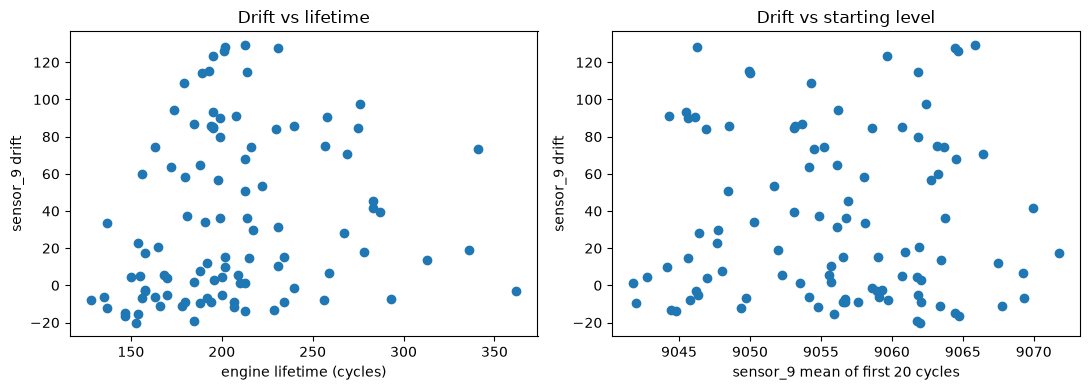

In [11]:
life = train.groupby("unit")["cycle"].max()
start_level = train.groupby("unit")["sensor_9"].apply(lambda s: s.iloc[:20].mean())
drift9 = pd.Series(end_minus_start("sensor_9"), index=life.index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(life, drift9)
axes[0].set_xlabel("engine lifetime (cycles)")
axes[0].set_ylabel("sensor_9 drift")
axes[0].set_title("Drift vs lifetime")

axes[1].scatter(start_level, drift9)
axes[1].set_xlabel("sensor_9 mean of first 20 cycles")
axes[1].set_ylabel("sensor_9 drift")
axes[1].set_title("Drift vs starting level")
plt.tight_layout()
plt.show()